# Phase 2 — Forecasting a Residential Property Price Index

## 1. Project objective

Predict **Korea's next quarterly nominal residential property price index** from information available at the end of the current quarter. We compare a simple persistence forecast with five scikit-learn regressors. This is a historical one-quarter-ahead experiment, not a forecast of today's market.

The source is the same BIS `nominal-index.csv` used in `hp_cleaning_visualization.ipynb`. Its `price` column is an **index with 2010 = 100**, not a transaction price in money. An index of 120 means the measured level is 20% above its 2010 reference level; it does not mean a home costs 120 units of currency.

We begin with one country because it lets us see every time split clearly. Korea was explored in Phase 1 and has 127 consecutive nonmissing quarterly values. A pooled multi-country model is discussed at the end.

## 2. Dataset inspection

We reproduce Phase 1's essential cleaning operation (`price.notna()`) without changing its notebook or source CSV. We keep the full nonmissing Korea history rather than Phase 1's 2002–2017 comparison window, because earlier Korea observations give the forecasting exercise more training history. Dates must be parsed and sorted before creating time features.

**Check the output:** it should show quarterly dates, missing-value counts, and one row per country/date. Missing values in other countries do not become invented values for Korea.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

data_path = Path('../house_pricedata/nominal-index.csv')
if not data_path.exists():  # also works when launched from the repository root
    data_path = Path('dat_learning/house_price/house_pricedata/nominal-index.csv')

raw = pd.read_csv(data_path, parse_dates=['date'])
print('Shape:', raw.shape)
print('Columns and types:\n', raw.dtypes)
print('Missing values:\n', raw.isna().sum())
#check how many missing value
print('Date range:', raw['date'].min().date(), 'to', raw['date'].max().date())
print('Country/date duplicates:', raw.duplicated(['country', 'date']).sum())
#check duplicated .duplicated
print('Months with an observed index:', sorted(raw.loc[raw['price'].notna(), 'date'].dt.month.unique()))
print(raw)


Shape: (12627, 3)
Columns and types:
 date       datetime64[ns]
country            object
price             float64
dtype: object
Missing values:
 date          0
country       0
price      8066
dtype: int64
Date range: 1966-03-31 to 2017-09-30
Country/date duplicates: 0
Months with an observed index: [np.int32(3), np.int32(6), np.int32(9), np.int32(12)]
            date                    country   price
0     1966-03-31  Emerging market economies     NaN
1     1966-03-31         Advanced economies     NaN
2     1966-03-31       United Arab Emirates     NaN
3     1966-03-31                    Austria     NaN
4     1966-03-31                  Australia     NaN
...          ...                        ...     ...
12622 2017-09-30                   Thailand  128.52
12623 2017-09-30                     Turkey  244.55
12624 2017-09-30              United States     NaN
12625 2017-09-30                  Euro area     NaN
12626 2017-09-30               South Africa  143.11

[12627 rows x 3 co

## 3. Prediction target

For a row at quarter **t**, the inputs include its observed index and earlier index values. The target is the index at **t + 1 quarter**. We exclude the final row because its next-quarter index is unknown in this historical file.

The dates are quarter ends (March, June, September, December). We check that Korea has no skipped quarter: otherwise `shift(-1)` would mean “next available observation,” which could be more than one quarter away.

In [ ]:
clean = raw.loc[raw['price'].notna()].copy()
clean['price'] = pd.to_numeric(clean['price'])
#pd.to_numeric()
korea = clean.loc[clean['country']=='Korea', ['date', 'price']].sort_values('date').reset_index(drop=True)
#[condition,[variable]].function
korea1=clean[clean["country"]=="Korea"].reset_index(drop=True)
korea['quarter_period'] = korea['date'].dt.to_period('Q')
#dt=Datatime

assert korea['quarter_period'].is_unique, 'Duplicate Korea quarters need investigation.'
assert korea['quarter_period'].astype(int).diff().iloc[1:].eq(1).all(), 'There are missing Korea quarters.'
print('Korea observations:', len(korea))
print('First / last:', korea.loc[0]['quarter_period'], korea['quarter_period'].iloc[-1])
display(korea.head(6), korea.tail(6))
#display make it look easier

Korea observations: 127
First / last: 1986Q1 2017Q3


,date,price,quarter_period
0,1986-03-31,42.38,1986Q1
1,1986-06-30,41.91,1986Q2
2,1986-09-30,41.59,1986Q3
3,1986-12-31,41.38,1986Q4
4,1987-03-31,41.09,1987Q1
5,1987-06-30,41.10,1987Q2


,date,price,quarter_period
121,2016-06-30,115.79,2016Q2
122,2016-09-30,116.19,2016Q3
123,2016-12-31,116.85,2016Q4
124,2017-03-31,117.05,2017Q1
125,2017-06-30,117.22,2017Q2
126,2017-09-30,117.87,2017Q3


## 4. Feature engineering

- `current_index`: the most recent known index. It also supplies the naive forecast.
- `lag_1`, `lag_2`: one and two quarters before the current quarter; these may reveal momentum or reversals.
- `rolling_mean_3`: the current and previous two indices; this smooths short-term variation.
- `change_1_pct`: percent change from the previous quarter to the current one.
- `year`, `quarter`: calendar context. Year can capture a long trend, while quarter can test for seasonality.

All shifts and rolling windows use only present or past data. Since we model one country, features cannot mix countries. A pooled model would need `groupby('country')` before every shift or rolling calculation. Lag features are correlated, so their model importances should be interpreted cautiously.

**Common mistake:** a centered rolling window or a negative shift used as an input would reveal future values. Here the negative shift appears only in the target.

In [61]:
model_data = korea[['date', 'price']].copy()
model_data['current_index'] = model_data['price']
model_data['lag_1'] = model_data['price'].shift(1)
model_data['lag_2'] = model_data['price'].shift(2)
model_data['rolling_mean_3'] = model_data['price'].rolling(3).mean()
#rolling().mean=moving average
model_data['change_1_pct'] = model_data['price'].pct_change(fill_method=None) * 100
#fill method=none mean not to fill a missing data
model_data['year'] = model_data['date'].dt.year
model_data['quarter'] = model_data['date'].dt.quarter
model_data['target_date'] = model_data['date'].shift(-1)
model_data['target_next_quarter'] = model_data['price'].shift(-1)

features = ['current_index', 'lag_1', 'lag_2', 'rolling_mean_3',
            'change_1_pct', 'year', 'quarter']
model_data = model_data.dropna(subset=features + ['target_next_quarter']).reset_index(drop=True)
assert (model_data['target_date'].dt.to_period('Q').astype(int)
        - model_data['date'].dt.to_period('Q').astype(int)).eq(1).all()
print('Usable prediction rows:', len(model_data))
display(model_data[['date', 'target_date'] + features + ['target_next_quarter']].head(6))

Usable prediction rows: 124


,date,target_date,current_index,lag_1,lag_2,rolling_mean_3,change_1_pct,year,quarter,target_next_quarter
0,1986-09-30,1986-12-31,41.59,41.91,42.38,41.960000,-0.763541,1986,3,41.38
1,1986-12-31,1987-03-31,41.38,41.59,41.91,41.626667,-0.504929,1986,4,41.09
2,1987-03-31,1987-06-30,41.09,41.38,41.59,41.353333,-0.700822,1987,1,41.10
3,1987-06-30,1987-09-30,41.10,41.09,41.38,41.190000,0.024337,1987,2,41.81
4,1987-09-30,1987-12-31,41.81,41.10,41.09,41.333333,1.727494,1987,3,43.92
5,1987-12-31,1988-03-31,43.92,41.81,41.10,42.276667,5.046640,1987,4,45.81


## 5. Train/test split

The **last 12 target quarters** are the final holdout. We choose that boundary before fitting or comparing models. Every training target occurs before every test target. The remaining training rows feed four expanding-window CV folds, each with 16 validation quarters. Each fold trains on earlier rows and validates on later rows.

The test is a **rolling one-quarter-ahead** test: for each test prediction, the current quarter's actual index is assumed known. Later test rows can therefore use actual values from earlier test quarters as lags. This would not be a valid multi-quarter forecast made all at once from the test boundary.

Random train/test splits or shuffled K-fold would let later quarters help train a model evaluated on earlier quarters. That can make forecasting scores misleading.

In [67]:
holdout_quarters = 12
train = model_data.iloc[:-holdout_quarters].copy()
test = model_data.iloc[-holdout_quarters:].copy()
X_train, y_train = train[features], train['target_next_quarter']
X_test, y_test = test[features], test['target_next_quarter']
cv = TimeSeriesSplit(n_splits=4, test_size=16)

assert train['target_date'].max() < test['target_date'].min()
assert len(train) > cv.n_splits * cv.test_size
print('Training targets:', train['target_date'].min().date(), 'to', train['target_date'].max().date(), f'({len(train)} rows)')
print('Final test targets:', test['target_date'].min().date(), 'to', test['target_date'].max().date(), f'({len(test)} rows)')
for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train), start=1):
    fit_rows, val_rows = train.iloc[fit_idx], train.iloc[val_idx]
    assert fit_rows['target_date'].max() < val_rows['target_date'].min()
    print(f"Fold {fold}: train {fit_rows['target_date'].min():%Y-%m-%d}–{fit_rows['target_date'].max():%Y-%m-%d} "
          f"({len(fit_rows)}); validate {val_rows['target_date'].min():%Y-%m-%d}–"
          f"{val_rows['target_date'].max():%Y-%m-%d} ({len(val_rows)})")

Training targets: 1986-12-31 to 2014-09-30 (112 rows)
Final test targets: 2014-12-31 to 2017-09-30 (12 rows)
Fold 1: train 1986-12-31–1998-09-30 (48); validate 1998-12-31–2002-09-30 (16)
Fold 2: train 1986-12-31–2002-09-30 (64); validate 2002-12-31–2006-09-30 (16)
Fold 3: train 1986-12-31–2006-09-30 (80); validate 2006-12-31–2010-09-30 (16)
Fold 4: train 1986-12-31–2010-09-30 (96); validate 2010-12-31–2014-09-30 (16)


## 6. Naive baseline

The persistence forecast is simply **next quarter = current quarter**. Price indices are often smooth, so this is a serious benchmark. A more complex model is useful only if it beats the baseline on the chosen validation metric. The baseline has no `.fit()` step.

In [14]:
baseline_train_mae = mean_absolute_error(y_train, X_train['current_index'])
print(f'Naive baseline training MAE: {baseline_train_mae:.3f} index points')
display(pd.DataFrame({
    'current_quarter': train['date'].tail(5).to_numpy(),
    'target_quarter': train['target_date'].tail(5).to_numpy(),
    'actual_next_index': y_train.tail(5).to_numpy(),
    'naive_prediction': X_train['current_index'].tail(5).to_numpy(),
}))

Naive baseline training MAE: 1.036 index points


,current_quarter,target_quarter,actual_next_index,naive_prediction
0,2013-06-30,2013-09-30,107.64,107.69
1,2013-09-30,2013-12-31,108.08,107.64
2,2013-12-31,2014-03-31,108.62,108.08
3,2014-03-31,2014-06-30,109.18,108.62
4,2014-06-30,2014-09-30,109.56,109.18


## 7. Scikit-learn model training

Every regressor receives all seven input columns. Linear regression combines them additively; the trees split the feature space; random forest averages many trees; gradient boosting and AdaBoost build ensembles in stages. Trees can model nonlinear behavior, but with a short, smooth series they can overfit and usually cannot extrapolate a new index level beyond what their training leaves saw. Linear regression may extrapolate, but a simple line may miss regime changes.

We keep tuning modest. `StandardScaler` is inside the linear model's `Pipeline`, so each CV fit learns its scaling from its own training fold. Trees do not need scaling. This single-country numeric experiment does not need `ColumnTransformer` or `OneHotEncoder`; those become appropriate when adding a country category to a pooled model.

In [15]:
models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Decision Tree': DecisionTreeRegressor(max_depth=4, min_samples_leaf=4, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=5,
                                           min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=2,
                                                   learning_rate=0.05, random_state=42),
    'AdaBoost': AdaBoostRegressor(n_estimators=100, learning_rate=0.05, random_state=42),
}

# One fit/predict example using only the first cross-validation fold.
example_fit_idx, example_val_idx = next(cv.split(X_train))
example_model = clone(models['Linear Regression'])
example_model.fit(X_train.iloc[example_fit_idx], y_train.iloc[example_fit_idx])
print('Example first three validation predictions:', example_model.predict(X_train.iloc[example_val_idx[:3]]).round(2))
print('Corresponding actual indices:', y_train.iloc[example_val_idx[:3]].to_numpy().round(2))

Example first three validation predictions: [57.39 57.09 58.75]
Corresponding actual indices: [57.45 58.36 58.68]


## 8. Cross-validation

`TimeSeriesSplit` expands the training history. `cross_val_score` returns one score per validation fold; scikit-learn negates losses such as MAE because its scoring convention is “higher is better.” `cross_validate` can return several metrics and training scores in one call. We demonstrate both with linear regression, then use an explicit loop so the same folds evaluate the naive baseline and all five models.

The **training score** measures fit on rows used to estimate a model. A **validation score** measures one later fold. The **CV score** below is the mean of four validation scores, with standard deviation showing variation across periods. The **final test score** comes only after model selection and fitting on all training rows.

In [16]:
linear_mae_folds = -cross_val_score(models['Linear Regression'], X_train, y_train,
                                    cv=cv, scoring='neg_mean_absolute_error')
linear_details = cross_validate(
    models['Linear Regression'], X_train, y_train, cv=cv,
    scoring={'mae': 'neg_mean_absolute_error',
             'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
    return_train_score=True,
)
print('cross_val_score validation MAE by fold:', linear_mae_folds.round(3))
print('cross_validate training MAE by fold:', (-linear_details['train_mae']).round(3))
print('cross_validate validation RMSE by fold:', (-linear_details['test_rmse']).round(3))
assert np.allclose(linear_mae_folds, -linear_details['test_mae'])

cross_val_score validation MAE by fold: [0.844 0.874 0.993 0.359]
cross_validate training MAE by fold: [0.801 0.746 0.748 0.766]
cross_validate validation RMSE by fold: [1.225 1.114 1.243 0.557]


In [17]:
def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R²': r2_score(actual, predicted),
    }


fold_rows = []
validation_predictions = []
for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train), start=1):
    X_fit, X_val = X_train.iloc[fit_idx], X_train.iloc[val_idx]
    y_fit, y_val = y_train.iloc[fit_idx], y_train.iloc[val_idx]
    for name in ['Naive Baseline', *models]:
        if name == 'Naive Baseline':
            predicted = X_val['current_index'].to_numpy()
        else:
            fitted = clone(models[name]).fit(X_fit, y_fit)
            predicted = fitted.predict(X_val)
        fold_rows.append({'Model': name, 'Fold': fold, **regression_metrics(y_val, predicted)})
        validation_predictions.extend(
            {'Model': name, 'Fold': fold, 'target_date': date,
             'actual': actual, 'predicted': estimate}
            for date, actual, estimate in zip(train.iloc[val_idx]['target_date'], y_val, predicted)
        )

fold_scores = pd.DataFrame(fold_rows)
cv_summary = fold_scores.groupby('Model', sort=False).agg(
    CV_MAE=('MAE', 'mean'), CV_MAE_SD=('MAE', 'std'),
    CV_MSE=('MSE', 'mean'), CV_RMSE=('RMSE', 'mean'),
    CV_RMSE_SD=('RMSE', 'std'), CV_R2=('R²', 'mean'), CV_R2_SD=('R²', 'std'),
).reset_index()
display(fold_scores.round(3), cv_summary.round(3))

,Model,Fold,MAE,MSE,RMSE,R²
0,Naive Baseline,1,1.117,2.517,1.587,0.895
1,Linear Regression,1,0.844,1.500,1.225,0.937
2,Decision Tree,1,2.079,5.702,2.388,0.761
3,Random Forest,1,1.621,3.970,1.993,0.834
4,Gradient Boosting,1,1.746,5.400,2.324,0.774
5,AdaBoost,1,1.871,5.355,2.314,0.776
6,Naive Baseline,2,1.029,1.450,1.204,0.759
7,Linear Regression,2,0.874,1.241,1.114,0.794
8,Decision Tree,2,9.256,91.685,9.575,-14.231
9,Random Forest,2,10.154,109.572,10.468,-17.202


,Model,CV_MAE,CV_MAE_SD,CV_MSE,CV_RMSE,CV_RMSE_SD,CV_R2,CV_R2_SD
0,Naive Baseline,0.990,0.185,1.800,1.319,0.282,0.801,0.079
1,Linear Regression,0.767,0.280,1.149,1.035,0.323,0.871,0.082
2,Decision Tree,7.871,4.356,81.478,8.199,4.359,-10.773,8.577
3,Random Forest,8.316,4.954,92.937,8.647,4.921,-12.515,9.920
4,Gradient Boosting,7.905,4.372,82.923,8.322,4.270,-11.166,8.278
5,AdaBoost,8.069,4.416,85.135,8.420,4.358,-11.475,8.512


## 9. Model evaluation on the final holdout

We select the model with the **lowest mean CV MAE** before looking at final test results. Then each model is fitted on the whole training period and evaluated once on the same 12-quarter holdout for comparison. The selected model remains fixed even if another model happens to score better on this holdout.

- **MAE:** average absolute error in index points; easy to interpret.
- **MSE:** average squared error; large misses receive extra weight.
- **RMSE:** square root of MSE, again in index points, but more sensitive to large misses than MAE.
- **R²:** compares squared error against always predicting the *mean of that evaluation period*. It can be negative when that mean benchmark is better. With only 12 test quarters, or a nearly flat index, R² can vary a lot; read it alongside MAE and RMSE.

In [18]:
selected_name = cv_summary.loc[cv_summary['CV_MAE'].idxmin(), 'Model']
print('Selected by CV MAE:', selected_name)

test_rows = []
test_predictions = {}
fitted_models = {}
for name in ['Naive Baseline', *models]:
    if name == 'Naive Baseline':
        predicted = X_test['current_index'].to_numpy()
    else:
        fitted_models[name] = clone(models[name]).fit(X_train, y_train)
        predicted = fitted_models[name].predict(X_test)
    test_predictions[name] = predicted
    test_rows.append({'Model': name, **regression_metrics(y_test, predicted)})

test_scores = pd.DataFrame(test_rows)
display(test_scores.round(3))

Selected by CV MAE: Linear Regression


,Model,MAE,MSE,RMSE,R²
0,Naive Baseline,0.693,0.673,0.820,0.883
1,Linear Regression,0.331,0.146,0.382,0.974
2,Decision Tree,6.592,49.187,7.013,-7.584
3,Random Forest,6.379,46.594,6.826,-7.132
4,Gradient Boosting,6.723,50.965,7.139,-7.895
5,AdaBoost,7.088,55.948,7.480,-8.764


## 10. Model comparison

This table is calculated from the folds and holdout above; it contains no placeholder scores. The standard deviations describe variation among four historical validation windows, not uncertainty bounds for future markets. Compare every model to the naive forecast before deciding that added complexity helped.

In [19]:
comparison = cv_summary.merge(test_scores, on='Model', validate='one_to_one')
comparison = comparison.rename(columns={
    'CV_MAE': 'CV MAE', 'CV_MAE_SD': 'CV MAE SD',
    'CV_RMSE': 'CV RMSE', 'CV_RMSE_SD': 'CV RMSE SD',
    'CV_R2': 'CV R²', 'CV_R2_SD': 'CV R² SD',
    'MAE': 'Test MAE', 'MSE': 'Test MSE',
    'RMSE': 'Test RMSE', 'R²': 'Test R²',
})
display(comparison[['Model', 'CV MAE', 'CV MAE SD', 'CV RMSE', 'CV RMSE SD',
                    'CV R²', 'CV R² SD', 'Test RMSE', 'Test MAE', 'Test MSE', 'Test R²']].round(3))
baseline_cv = comparison.loc[comparison['Model'].eq('Naive Baseline'), 'CV MAE'].iloc[0]
selected_cv = comparison.loc[comparison['Model'].eq(selected_name), 'CV MAE'].iloc[0]
print(f'Selected model CV MAE: {selected_cv:.3f}; naive CV MAE: {baseline_cv:.3f}')
print('Did the selected model beat the naive baseline on CV MAE?', selected_cv < baseline_cv)

,Model,CV MAE,CV MAE SD,CV RMSE,CV RMSE SD,CV R²,CV R² SD,Test RMSE,Test MAE,Test MSE,Test R²
0,Naive Baseline,0.990,0.185,1.319,0.282,0.801,0.079,0.820,0.693,0.673,0.883
1,Linear Regression,0.767,0.280,1.035,0.323,0.871,0.082,0.382,0.331,0.146,0.974
2,Decision Tree,7.871,4.356,8.199,4.359,-10.773,8.577,7.013,6.592,49.187,-7.584
3,Random Forest,8.316,4.954,8.647,4.921,-12.515,9.920,6.826,6.379,46.594,-7.132
4,Gradient Boosting,7.905,4.372,8.322,4.270,-11.166,8.278,7.139,6.723,50.965,-7.895
5,AdaBoost,8.069,4.416,8.420,4.358,-11.475,8.512,7.480,7.088,55.948,-8.764


Selected model CV MAE: 0.767; naive CV MAE: 0.990
Did the selected model beat the naive baseline on CV MAE? True


### Results from the verified run

The following values were calculated by running this notebook in the `learnjupyter` environment (pandas 2.3.3, scikit-learn 1.9.1). The live table above is the source of truth when you rerun the notebook.

| Model | CV MAE | CV RMSE | CV R² | Test RMSE |
|---|---:|---:|---:|---:|
| Naive Baseline | 0.990 | 1.319 | 0.801 | 0.820 |
| Linear Regression | 0.767 | 1.035 | 0.871 | 0.382 |
| Decision Tree | 7.871 | 8.199 | -10.773 | 7.013 |
| Random Forest | 8.316 | 8.647 | -12.515 | 6.826 |
| Gradient Boosting | 7.905 | 8.322 | -11.166 | 7.139 |
| AdaBoost | 8.069 | 8.420 | -11.475 | 7.480 |

The tree ensembles fit patterns within earlier index ranges, but they struggle when later index levels move beyond their training range. Their negative CV R² means they performed worse than predicting each validation period's mean. Linear regression did better here, but this result describes these historical folds rather than a guarantee for future housing markets. The final test RMSE is based on only 12 quarters.

## 11. Visualizations

Plots use **index points**, not currency. The first chart shows where training, one example CV validation window, and final test lie in time. The selected prediction chart uses CV predictions for validation and separately shows final test predictions. Validation points come from models fitted only to earlier data in their fold.

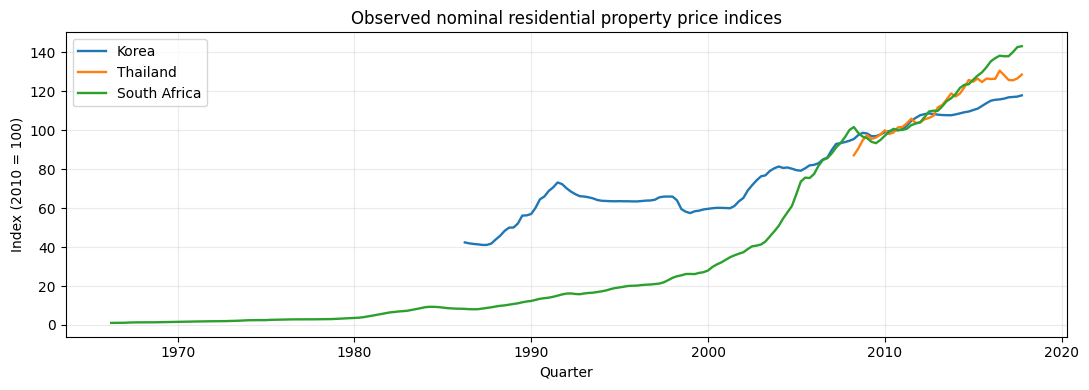

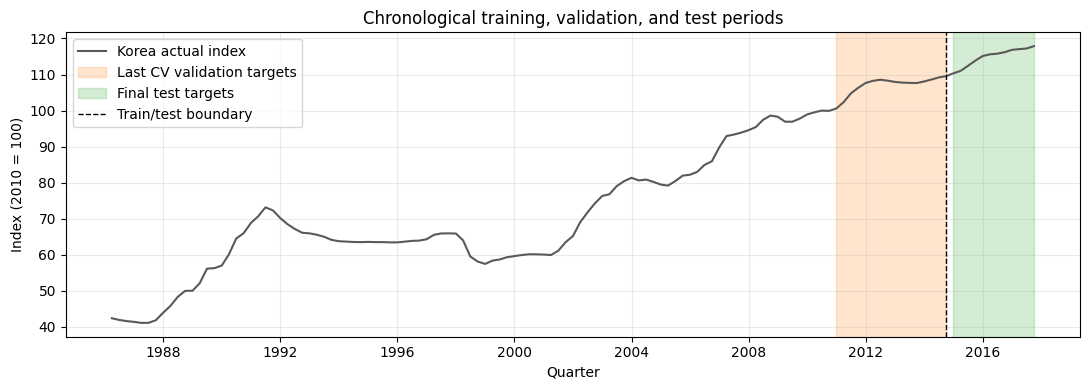

In [20]:
fig, ax = plt.subplots(figsize=(11, 4))
for country in ['Korea', 'Thailand', 'South Africa']:
    country_data = clean.loc[clean['country'].eq(country)].sort_values('date')
    ax.plot(country_data['date'], country_data['price'], label=country, linewidth=1.7)
ax.set(title='Observed nominal residential property price indices',
       xlabel='Quarter', ylabel='Index (2010 = 100)')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(korea['date'], korea['price'], color='0.35', label='Korea actual index')
last_fit_idx, last_val_idx = list(cv.split(X_train))[-1]
last_val_dates = train.iloc[last_val_idx]['target_date']
ax.axvspan(last_val_dates.min(), last_val_dates.max(), alpha=0.20,
           color='tab:orange', label='Last CV validation targets')
ax.axvspan(test['target_date'].min(), test['target_date'].max(), alpha=0.20,
           color='tab:green', label='Final test targets')
ax.axvline(train['target_date'].max(), color='black', linestyle='--', linewidth=1,
           label='Train/test boundary')
ax.set(title='Chronological training, validation, and test periods',
       xlabel='Quarter', ylabel='Index (2010 = 100)')
ax.legend(loc='upper left')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

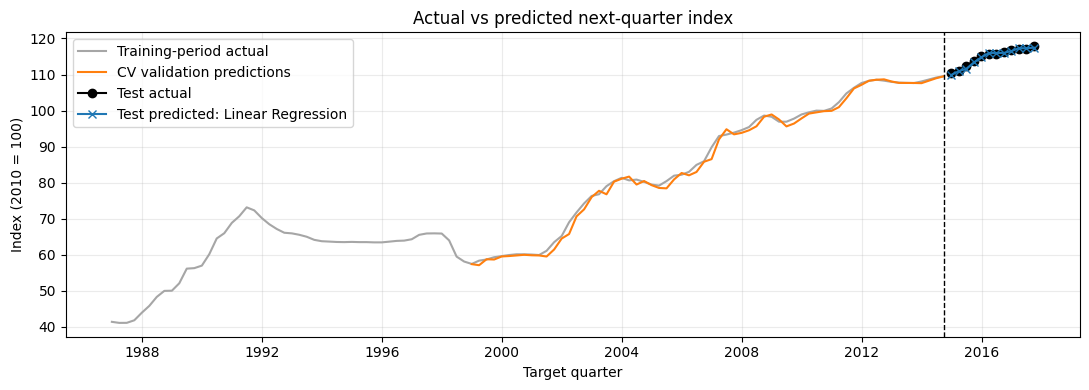

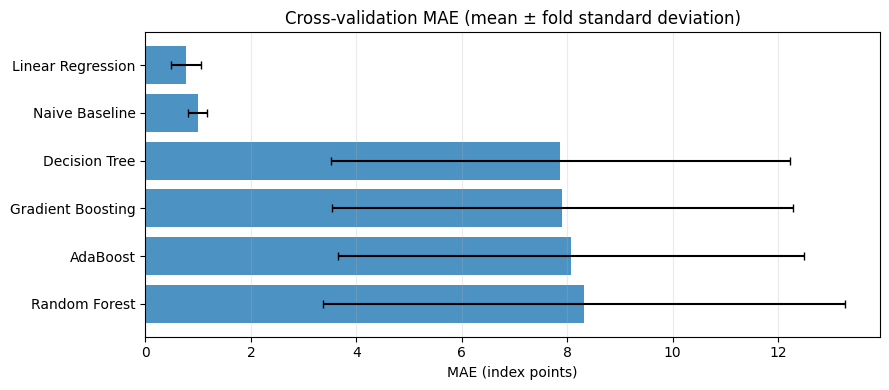

In [21]:
selected_validation = pd.DataFrame(validation_predictions)
selected_validation = selected_validation.loc[selected_validation['Model'].eq(selected_name)]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train['target_date'], y_train, color='0.65', label='Training-period actual')
ax.plot(selected_validation['target_date'], selected_validation['predicted'],
        color='tab:orange', label='CV validation predictions')
ax.plot(test['target_date'], y_test, color='black', marker='o', label='Test actual')
ax.plot(test['target_date'], test_predictions[selected_name],
        color='tab:blue', marker='x', label=f'Test predicted: {selected_name}')
ax.axvline(train['target_date'].max(), color='black', linestyle='--', linewidth=1)
ax.set(title='Actual vs predicted next-quarter index',
       xlabel='Target quarter', ylabel='Index (2010 = 100)')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

ordered = comparison.sort_values('CV MAE')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ordered['Model'], ordered['CV MAE'], xerr=ordered['CV MAE SD'],
        color='tab:blue', alpha=0.8, capsize=3)
ax.invert_yaxis()
ax.set(title='Cross-validation MAE (mean ± fold standard deviation)',
       xlabel='MAE (index points)', ylabel='')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

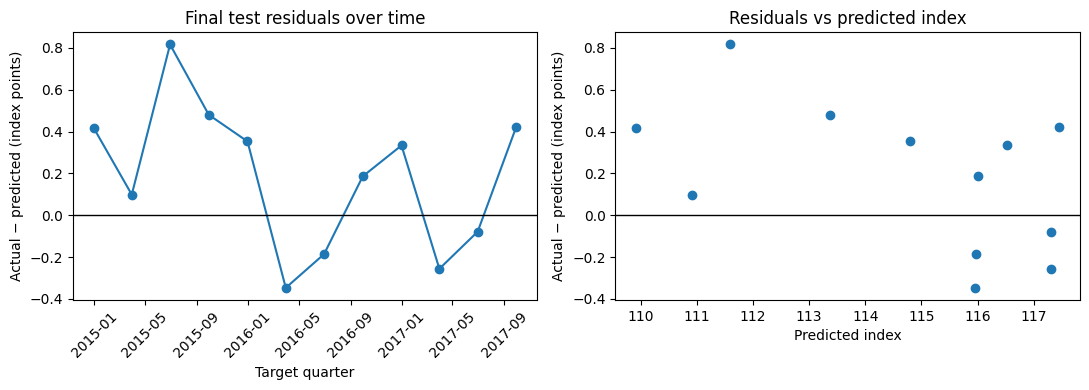

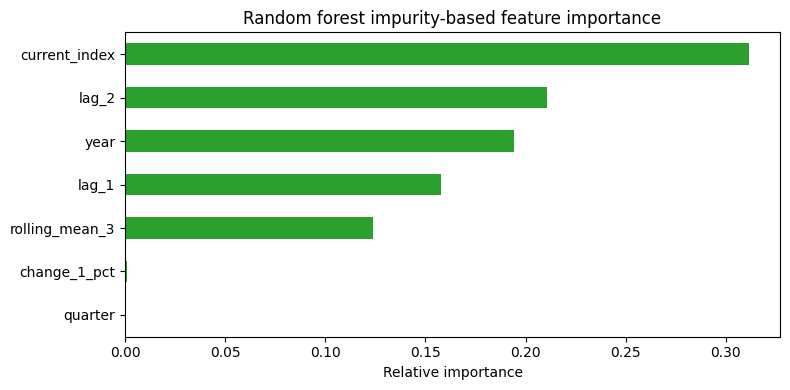

In [22]:
residuals = y_test.to_numpy() - test_predictions[selected_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(test['target_date'], residuals, marker='o')
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(title='Final test residuals over time', xlabel='Target quarter',
            ylabel='Actual − predicted (index points)')
axes[0].tick_params(axis='x', rotation=45)
axes[1].scatter(test_predictions[selected_name], residuals)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(title='Residuals vs predicted index', xlabel='Predicted index',
            ylabel='Actual − predicted (index points)')
plt.tight_layout()
plt.show()

# Show a supported tree model even when CV selects the naive or linear model.
forest = fitted_models['Random Forest']
importance = pd.Series(forest.feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
importance.plot.barh(ax=ax, color='tab:green')
ax.set(title='Random forest impurity-based feature importance',
       xlabel='Relative importance', ylabel='')
plt.tight_layout()
plt.show()

## 12. Conclusions and next steps

Use the computed comparison table above to state which model won by **CV MAE**, whether it beat the naive baseline, and how it behaved on the untouched final test. Do not select a new model because of its test score. A low training error with much worse CV error suggests overfitting. CV variation across folds can reveal changing market periods.

**Limits:** this historical series ends in 2017 Q3. It contains an index, no property-level prices and no economic predictors. Twelve test quarters give a useful teaching holdout but an imprecise estimate of future performance. Index levels are strongly persistent, so the naive baseline may be hard to beat. Feature importance shows how this fitted forest split the data; it does **not** establish causes of property price changes.

### Country-specific vs pooled multi-country models

| Approach | Advantage | Limitation |
|---|---|---|
| Separate country model (used here) | Clear timeline and country-specific behavior | Fewer observations; one model per country |
| One pooled model | Shares observations across countries; country can be one-hot encoded | Countries may have different dynamics and coverage; regional aggregates overlap individual countries |

For a later pooled experiment, first sort by **country and quarter** and calculate lags with `groupby('country')`. Put country encoding in a `ColumnTransformer` inside a `Pipeline`, fitting it separately in each training fold. Split by **shared target-quarter boundaries**: in every fold, the maximum training target date must precede the minimum validation target date across *all* countries. `TimeSeriesSplit` on individual panel rows is unsuitable because many countries share each date. Use a custom loop over unique quarters and keep a final shared-quarter holdout. Decide how to handle the `Advanced economies`, `Emerging market economies`, and `Euro area` aggregates before treating all rows as independent countries.